In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from tensorflow.keras import models
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from tensorflow.keras import models, layers

Retrieve and merge data

In [9]:
data_path = '../Data/combined_data_by_year/'

dam = pd.read_parquet(f'{data_path}dam_data_2023_2026.parquet')
rtm = pd.read_parquet(f'{data_path}rtm_data_2023_2026.parquet')
load = pd.read_parquet(f'{data_path}load_data_2023_2026.parquet')
outage = pd.read_parquet(f'{data_path}outage_data_2023_2026.parquet')
solar = pd.read_parquet(f'{data_path}solar_data_2023_2026.parquet')
wind = pd.read_parquet(f'{data_path}wind_data_2023_2026.parquet')

data = pd.merge(dam, rtm, on='interval_end_utc', suffixes=('_dam', '_rtm'))
data = pd.merge(data, load, on='interval_end_utc', suffixes=('', '_load'))
data = pd.merge(data, outage, on='interval_end_utc', suffixes=('', '_outage'))
data = pd.merge(data, solar, on='interval_end_utc', suffixes=('', '_solar'))
data = pd.merge(data, wind, on='interval_end_utc', suffixes=('', '_wind'))

data = data.sort_values('interval_end_utc').reset_index(drop=True)

data.loc[data['lmp_dam'] > 132, 'lmp_dam'] = 132
data.loc[data['lmp_rtm'] > 132, 'lmp_rtm'] = 132

load_forecast = data['load_forecast'].astype(float).values.reshape(-1, 1) 
miso_solar = data['miso'].astype(float).values.reshape(-1, 1)
miso_wind = data['miso_wind'].astype(float).values.reshape(-1, 1)
lmp_dam = data['lmp_dam'].astype(float).values.reshape(-1, 1)
lmp_rtm = data['lmp_rtm'].astype(float).values.reshape(-1, 1) #target/label


Build X matrix and y target

In [10]:


features = np.concatenate((
    lmp_dam,
    load_forecast,
    miso_solar,
    miso_wind
), axis=1)

window_size = 288
forecast_size = 288

X = []
y = []
target_dates = []

for i in range(window_size, len(data) - forecast_size + 1):
    X.append(features[i - window_size:i, :])

    y.append(
        lmp_rtm[i:i + forecast_size, 0]
    )

    target_dates.append(
        data['interval_end_utc'].iloc[i:i + forecast_size].values
    )

X = np.array(X)
y = np.array(y)




Split data into test and training sets

In [11]:
X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
    X, y, target_dates, test_size=0.2, shuffle=False
)

MemoryError: Unable to allocate 2.84 GiB for an array with shape (1325392, 288) and data type float64

Converting from float64 to float32 to reduce memory usage

In [ ]:
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

Scale data

In [ ]:

scaler_x = MinMaxScaler(feature_range=(0, 1))

scaler_x.fit(X_train.reshape(-1, X_train.shape[2]))

scaled_x_training = scaler_x.transform(
    X_train.reshape(-1, X_train.shape[2])
)

scaled_x_testing = scaler_x.transform(
    X_test.reshape(-1, X_test.shape[2])
)

X_train = scaled_x_training.reshape(
    X_train.shape[0],
    X_train.shape[1],
    X_train.shape[2]
)

X_test = scaled_x_testing.reshape(
    X_test.shape[0],
    X_test.shape[1],
    X_test.shape[2]
)

scaler_y = MinMaxScaler(feature_range=(0, 1))

y_train = scaler_y.fit_transform(
    y_train.reshape(-1, 1)
).reshape(y_train.shape)

y_test = scaler_y.transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)

Build and train model. These parameters are optimal for this dataset.

In [ ]:

model = models.Sequential([
    layers.Input((window_size, 4)),
    layers.LSTM(units=32, return_sequences=True),
    layers.Dropout(0.1),
    layers.LSTM(32),
    layers.Dense(288)
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="mse"
)



early_stopping = EarlyStopping(
    mode="min",
    patience=3,
    min_delta=1e-3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

Epoch 1/20
   77/18639 ━━━━━━━━━━━━━━━━━━━━ 25:49 83ms/step - loss: 0.1124

KeyboardInterrupt: 

Use model on test data, and look at its performance

In [ ]:
# Get predictions
y_pred = model.predict(X_test)

# Inverse transform predictions
y_pred_original = scaler_y.inverse_transform(
    y_pred.reshape(-1, 1)
).reshape(y_pred.shape)

# Inverse transform actual values
y_test_original = scaler_y.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)

# Calculate RMSE
rmse = np.sqrt(
    mean_squared_error(
        y_test_original.flatten(),
        y_pred_original.flatten()
    )
)

print("Test RMSE:", rmse)

# Calculate R-squared
r2 = r2_score(
    y_test_original.flatten(),
    y_pred_original.flatten()
)

print("Test R²:", r2)

10355/10355 ━━━━━━━━━━━━━━━━━━━━ 172s 17ms/step
Test RMSE: 14.701975
Test R²: 0.2599483132362366


Predict on all data

In [ ]:
X_all_scaled = scaler_x.transform(
    X.reshape(-1, X.shape[2])
).reshape(X.shape)
# Predict all samples
y_pred_all = model.predict(X_all_scaled)

# Inverse transform predictions
y_pred_all_original = scaler_y.inverse_transform(
    y_pred_all.reshape(-1, 1)
).reshape(y_pred_all.shape)

Add predictions to parquet file

In [ ]:
predictions_df = pd.DataFrame(
    y_pred_all_original,
    columns=[f'prediction_{i}' for i in range(288)]
)

actual_df = pd.DataFrame(
    y,
    columns=[f'actual_{i}' for i in range(288)]
)

dates_df = pd.DataFrame(
    target_dates,
    columns=[f'date_{i}' for i in range(288)]
)

predictions_df = pd.concat(
    [dates_df, actual_df, predictions_df],
    axis=1
)

predictions_df.to_parquet(
    'lstm_predictions_entire_dataset.parquet',
    index=False
)

Plot 1 sample

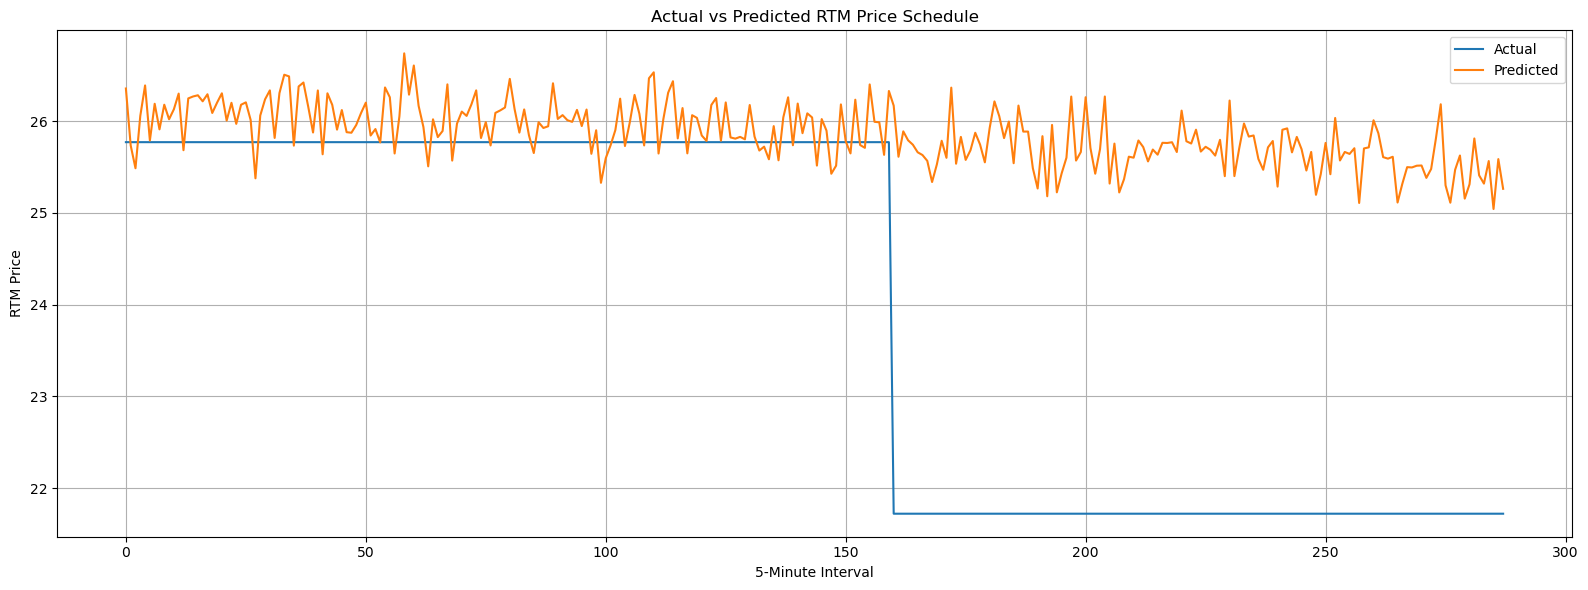

In [ ]:
actual_schedule = y_test_original[4]
predicted_schedule = y_pred_original[4]
schedule_dates = dates_test[4]

plt.figure(figsize=(16, 6))

plt.plot(schedule_dates, actual_schedule, label='Actual')
plt.plot(schedule_dates, predicted_schedule, label='Predicted')

plt.title('Actual vs Predicted RTM Price Schedule')
plt.xlabel('Date')
plt.ylabel('RTM Price')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Plot all test data

C:\Users\atoll\AppData\Local\Temp\ipykernel_11004\1790468463.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\atoll\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


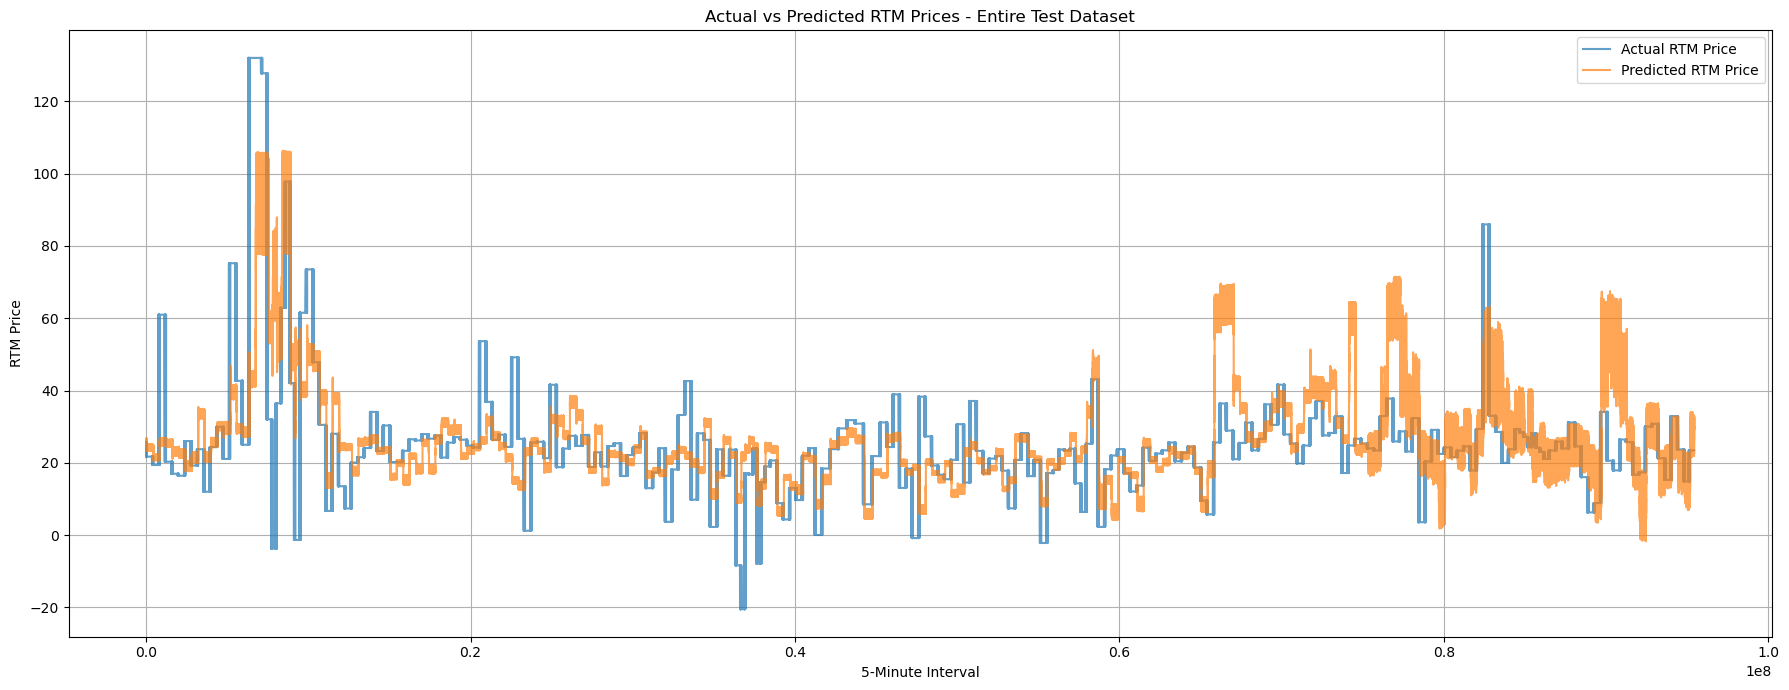

In [ ]:
# Flatten all test schedules into one continuous sequence
actual_all = y_test_original.flatten()
predicted_all = y_pred_original.flatten()

# Plot all actual and predicted values
plt.figure(figsize=(18, 7))

plt.plot(actual_all, label='Actual RTM Price', alpha=0.7)
plt.plot(predicted_all, label='Predicted RTM Price', alpha=0.7)

plt.title('Actual vs Predicted RTM Prices - Entire Test Dataset')
plt.xlabel('5-Minute Interval')
plt.ylabel('RTM Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()